# Gasto público en pensiones

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "gasto-pensiones-pib"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público en pensiones"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/
MAX_DIF_ESPANA = 0.5  # puntos del PIB: diferencia máxima admitida entre SOCX y ESSPROS en España

## 1. Contexto

**Qué mide.** Lo que gastan todas las administraciones públicas en pensiones de jubilación y de supervivencia (viudedad y orfandad) y en otras prestaciones en dinero a las personas mayores, en porcentaje del PIB. Es el gasto que paga el sistema público de pensiones de cada país, financiado con cotizaciones o con impuestos.

**Cómo se lee.** Un valor de 12 significa que ese año las pensiones públicas de jubilación y supervivencia costaron el equivalente al 12 % de todo lo que produjo la economía.

**Limitaciones.**
- **Todas las administraciones.** En España incluye las pensiones contributivas de la Seguridad Social, las no contributivas y las de clases pasivas de los funcionarios, que paga el Estado; no incluye las pensiones de incapacidad permanente, que la OCDE cuenta aparte (ver `gasto-prestaciones-no-pensiones`).
- **Depende de la demografía.** Un gasto mayor puede deberse a pensiones más altas o a que haya más personas mayores (ver `tasa-dependencia-mayores`), y en un año de recesión sube porque cae el PIB.
- La base de gasto social de la OCDE (SOCX) publica los datos con unos años de retraso. La UE-27 sale de otra fuente, Eurostat, con la misma definición; la sección 3 comprueba que las dos coinciden para España.
- Solo es el gasto público: no incluye los planes de pensiones de empresa ni individuales, que pesan mucho en países como Estados Unidos o Canadá.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** OCDE, base de gasto social (SOCX, `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0`): programa «vejez y supervivencia» (`TP01`), gasto público (`ES10`), prestaciones en dinero (`C`), en % del PIB (`PT_B1GQ`). La media de la OCDE es el área `OECD`.
- **UE-27:** Eurostat, gasto en pensiones (`spr_exp_pens`, ESSPROS) en % del PIB, sumando las pensiones de jubilación (`OLD`), de jubilación anticipada (`AOLD`), parciales (`PART`) y de supervivencia (`SRV`). Se dejan fuera las de incapacidad (`DIS`, `ERRC`) y la jubilación anticipada por motivos del mercado de trabajo (`ERLM`), que SOCX tampoco incluye en vejez y supervivencia.
- **Comprobación:** las mismas partidas de ESSPROS y el total de pensiones (`TOTAL`) para España.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

# SOCX: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.EXPEND_SOURCE.SPENDING_TYPE.PROGRAMME_TYPE.PRICE_BASE
DATAFLOW_SOCX = "OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0"
CLAVE_SOCX = "{AREA}.A.SOCX.PT_B1GQ.ES10.C.TP01._Z"
socx, fuentes_socx = oecd.get(
    DATAFLOW_SOCX, CLAVE_SOCX, areas={"ESP": "espana", "OECD": "ocde", "USA": "eeuu", "CAN": "canada"}, desde=DESDE
)

PARTIDAS = ["OLD", "AOLD", "PART", "SRV"]  # vejez y supervivencia
ess = {}
for b in [*PARTIDAS, "DIS", "TOTAL"]:
    ess[b], f = eurostat.get(
        "spr_exp_pens", {"freq": "A", "spdepb": b, "spdepm": "TOTAL", "unit": "PC_GDP"}, desde=DESDE
    )
    if b == "OLD":
        fuentes_ess = f
print(socx.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max
serie             
canada  1980  2022
eeuu    1980  2023
espana  1980  2021
ocde    1980  2021


## 3. Transformación

- **España, OCDE, EE. UU. y Canadá:** SOCX sin transformar.
- **UE-27:** suma de las partidas de jubilación y supervivencia de ESSPROS (las que no tienen dato cuentan como cero si alguna otra lo tiene).
- Comprobación: SOCX frente a la misma suma de ESSPROS para España.

In [ ]:
serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]


def suma_ess(geo):
    return pd.concat([serie(ess[b], geo) for b in PARTIDAS], axis=1).sum(axis=1, min_count=1)


ue = suma_ess("ue27").dropna()
df = pd.concat(
    [socx, pd.DataFrame({"serie": "ue27", "periodo": ue.index, "valor": ue.values})], ignore_index=True
)
assert df["valor"].between(1, 25).all(), "gasto fuera de rango: ¿unidades?"
HOY = fuentes_socx[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, "DSD_SOCX_AGG@DF_SOCX_AGG (TP01, ES10, C, PT_B1GQ)", f.url, f.fecha_consulta)
    for f in fuentes_socx
] + [
    FuenteMeta("ue27", eurostat.ORGANISMO, "spr_exp_pens (spdepb=OLD+AOLD+PART+SRV, spdepm=TOTAL, unit=PC_GDP)",
               fuentes_ess[0].url, HOY)
]

comp = pd.DataFrame({
    "SOCX TP01": serie(socx, "espana"),
    "ESSPROS jubilación y supervivencia": suma_ess("espana"),
    "ESSPROS total pensiones": serie(ess["TOTAL"], "espana"),
    "ESSPROS incapacidad (DIS)": serie(ess["DIS"], "espana"),
})
comp["dif. (SOCX − ESSPROS j. y s.)"] = comp["SOCX TP01"] - comp["ESSPROS jubilación y supervivencia"]
display(comp.round(2).dropna(subset=["SOCX TP01"]).loc[1995:])
dif = comp["dif. (SOCX − ESSPROS j. y s.)"].dropna()
DIF_MAX, DIF_MIN = dif.max(), dif.min()
COMUN = (int(dif.index.min()), int(dif.index.max()))
assert dif.abs().max() <= MAX_DIF_ESPANA, "SOCX y ESSPROS se separan en España: revisar las partidas de la UE-27"
ULT_ES = int(serie(socx, "espana").index.max())
ULT_ESS = int(suma_ess("espana").dropna().index.max())

,SOCX TP01,ESSPROS jubilación y supervivencia,ESSPROS total pensiones,ESSPROS incapacidad (DIS),dif. (SOCX − ESSPROS j. y s.)
periodo,,,,,
1995,8.75,8.51,9.82,1.24,0.24
1996,8.91,8.69,9.97,1.24,0.22
1997,8.82,8.61,9.85,1.20,0.21
1998,8.53,8.34,9.64,1.25,0.19
1999,8.33,8.14,9.37,1.18,0.19
2000,8.12,8.19,9.39,1.17,-0.07
2001,7.83,7.93,9.09,1.12,-0.10
2002,7.80,7.91,9.04,1.12,-0.11
2003,7.69,7.83,8.96,1.11,-0.14


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


NOTAS = [
    "España, OCDE, EE. UU. y Canadá: OCDE, base de gasto social (SOCX, DSD_SOCX_AGG@DF_SOCX_AGG), gasto público en "
    "prestaciones en dinero de vejez y supervivencia (TP01, ES10, C), en % del PIB. Incluye el gasto de todas las "
    "administraciones; en España, también las pensiones no contributivas y las de clases pasivas de los "
    "funcionarios, que paga el Estado.",
    "UE-27: Eurostat, gasto en pensiones (spr_exp_pens, ESSPROS), suma de las pensiones de jubilación, jubilación "
    "anticipada, parciales y de supervivencia, en % del PIB; sin las de incapacidad ni la jubilación anticipada por "
    "motivos del mercado de trabajo. Agregado de composición actual (EU27_2020).",
    f"España en las dos fuentes: de {COMUN[0]} a {COMUN[1]}, SOCX y la misma suma de ESSPROS difieren entre "
    f"{fmt(DIF_MIN, 2)} y {fmt(DIF_MAX, 2)} puntos del PIB. ESSPROS llega hasta {ULT_ESS} y SOCX, hasta {ULT_ES}.",
    "No incluye las pensiones de incapacidad, que la OCDE cuenta en otro programa, ni los planes de pensiones "
    "privados, de empresa o individuales.",
    "El porcentaje del PIB sube cuando hay más personas mayores o cuando cae el PIB, como en 2020, aunque no cambien "
    "las pensiones.",
]
for n in NOTAS:
    print("-", n)

- España, OCDE, EE. UU. y Canadá: OCDE, base de gasto social (SOCX, DSD_SOCX_AGG@DF_SOCX_AGG), gasto público en prestaciones en dinero de vejez y supervivencia (TP01, ES10, C), en % del PIB. Incluye el gasto de todas las administraciones; en España, también las pensiones no contributivas y las de clases pasivas de los funcionarios, que paga el Estado.
- UE-27: Eurostat, gasto en pensiones (spr_exp_pens, ESSPROS), suma de las pensiones de jubilación, jubilación anticipada, parciales y de supervivencia, en % del PIB; sin las de incapacidad ni la jubilación anticipada por motivos del mercado de trabajo. Agregado de composición actual (EU27_2020).
- España en las dos fuentes: de 1995 a 2021, SOCX y la misma suma de ESSPROS difieren entre −0,32 y 0,24 puntos del PIB. ESSPROS llega hasta 2024 y SOCX, hasta 2021.
- No incluye las pensiones de incapacidad, que la OCDE cuenta en otro programa, ni los planes de pensiones privados, de empresa o individuales.
- El porcentaje del PIB sube cuando ha

## 4. Visualización

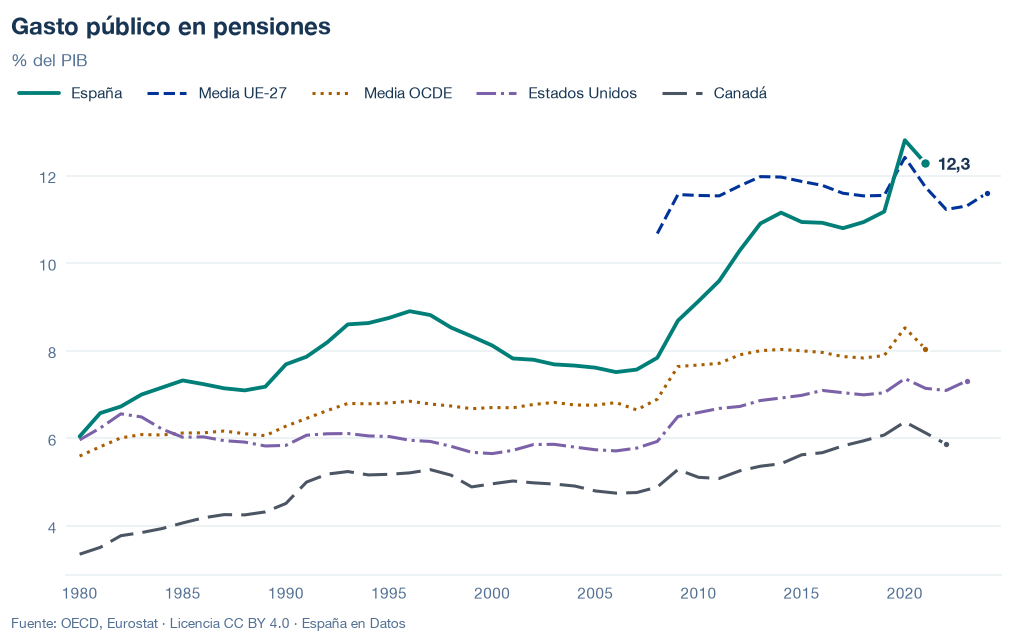

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-pensiones-pib.json y data/gasto-pensiones-pib.csv


## 6. Fuentes, notas y licencia

- OCDE, SOCX: `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0` (`TP01`, `ES10`, `C`, `PT_B1GQ`) para España, la OCDE, EE. UU. y Canadá.
- Eurostat, `spr_exp_pens` (`OLD`, `AOLD`, `PART`, `SRV`; y `DIS` y `TOTAL` para la comprobación) para la UE-27.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.